# Challenge 3 – Customer Segmentation và Next Best Action

Đầu vào:
- `bi10_eda.duckdb` (các bảng EN_* nạp từ `clean_data`, giống notebook Challenge 2);
- `output/engagement_score.csv`, điểm Engagement của Challenge 2;
- file điểm Financial Health của Challenge 1 (`customer_financial_health_BUSINESS.csv` hoặc `customer_financial_health_FINAL.csv`, thư mục `C1_CHALLENGE1_FINAL/`).

Mọi con số trong phần nhận xét đều lấy từ bảng kết quả của một ô code trong notebook.

In [1]:
import os, glob
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)

OUT_DIR = 'output'; HINH_DIR = f'{OUT_DIR}/figures_c3'; os.makedirs(HINH_DIR, exist_ok=True)
MAU = {'xanh': '#2a78d6', 'cam': '#eb6834', 'chu': '#0b0b0b', 'chu_phu': '#52514e', 'luoi': '#e4e3df', 'nen': '#fcfcfb', 'nhat': '#c9c8c3'}
CMAP_XANH = LinearSegmentedColormap.from_list('xanh', ['#eef4fc', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({'figure.facecolor': MAU['nen'], 'axes.facecolor': MAU['nen'], 'savefig.facecolor': MAU['nen'],
                     'axes.edgecolor': MAU['nhat'], 'axes.labelcolor': MAU['chu_phu'], 'xtick.color': MAU['chu_phu'], 'ytick.color': MAU['chu_phu'],
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': MAU['luoi'], 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlecolor': MAU['chu'],
                     'axes.titlelocation': 'left', 'font.size': 9.5, 'legend.frameon': False})
def so(x, n=1):
    return f'{x:,.{n}f}'.replace(',', ' ').replace('.', ',').replace(' ', '.')
def luu_hinh(fig, ten):
    fig.savefig(f'{HINH_DIR}/{ten}.png', dpi=200, bbox_inches='tight'); plt.show()

con = duckdb.connect('bi10_eda.duckdb')
con.execute("SET memory_limit='1GB'"); con.execute("SET preserve_insertion_order=false")
def q(sql):
    return con.sql(sql).df()
T_CHOT = '2025-06-05'   # ngày chốt, giống Challenge 2

# Tìm file điểm Financial Health của Challenge 1
ung_vien = [p for d in ['task 1 data', 'C1_CHALLENGE1_FINAL', '.', OUT_DIR] for p in sorted(glob.glob(f'{d}/customer_financial_health_*.csv'))]
FHS_FILE = next((p for p in ung_vien if 'BUSINESS' in p), ung_vien[0] if ung_vien else None)
print('File Financial Health dùng:', FHS_FILE)

File Financial Health dùng: task 1 data/customer_financial_health_BUSINESS.csv


## 0. Ghép hai điểm và kiểm tra đầu vào

> **Câu hỏi của mục này:** Hai điểm của Challenge 1 và Challenge 2 có ghép được với nhau cho đúng từng khách không?
>
> **Cách làm:** đọc điểm Financial Health (FHS) từ file của Challenge 1, tính lại điểm Engagement tại ngày chốt theo đúng bảng điểm của Challenge 2 và so với file của Challenge 2, rồi đối chiếu cờ Written off với dữ liệu hợp đồng.

In [2]:
# (1) Financial Health Score của Challenge 1
con.execute(f"""CREATE OR REPLACE TABLE C3_FHS AS
    SELECT SKP_CLIENT, FINANCIAL_HEALTH_SCORE AS FHS, SCORE_EVIDENCE_FLAG AS FHS_EVIDENCE, FINANCIAL_HEALTH_SEGMENT AS FHS_SEGMENT_C1,
           BUSINESS_ACTION_GUARDRAIL AS C1_GUARDRAIL, WRITTEN_OFF_OBSERVED::INT AS WO_C1
    FROM read_csv('{FHS_FILE}', header=true)""")
display(q("""SELECT FHS_EVIDENCE, count(*) AS so_khach, count(FHS) AS co_FHS, round(min(FHS), 1) AS fhs_min, round(max(FHS), 1) AS fhs_max
             FROM C3_FHS GROUP BY 1 ORDER BY 2 DESC"""))

# (2) Engagement Score tại một ngày T, theo đúng bảng điểm của Challenge 2 (output/engagement_points.csv)
def diem_engagement(T):
    return q(f"""
    WITH goi AS (SELECT * FROM EN_CALL WHERE coalesce(CODE_DISPOSITION, '') NOT LIKE 'OWN%'
                 AND TIME_OF_CALL_START < TIMESTAMP '{T}' AND TIME_OF_CALL_START >= TIMESTAMP '{T}' - INTERVAL 90 DAY),
    c AS (SELECT SKP_CLIENT, count(DISTINCT CALL_ID) AS n_goi,
                 count(DISTINCT CALL_ID) FILTER (WHERE CALL_RESULT_SYSTEM = 'ANSWER' OR CALL_TYPE = 'Inbound') AS n_ph,
                 date_diff('day', max(TIME_OF_CALL_START) FILTER (WHERE CALL_RESULT_SYSTEM = 'ANSWER' OR CALL_TYPE = 'Inbound'), TIMESTAMP '{T}') AS ngay_ph
          FROM goi GROUP BY 1),
    pb AS (SELECT SKP_CLIENT, date_diff('day', max(DTIME_EVENT), TIMESTAMP '{T}') AS ngay_xv FROM EN_PB WHERE DTIME_EVENT < TIMESTAMP '{T}' GROUP BY 1),
    l AS (SELECT SKP_CLIENT, count(DISTINCT date_trunc('month', DTIME_CREATED)) AS thang_lead FROM EN_LEADS WHERE DTIME_CREATED < TIMESTAMP '{T}' GROUP BY 1),
    sp AS (SELECT SKP_CLIENT, count(DISTINCT PRODUCT_GROUP) AS sp
           FROM (SELECT SKP_CLIENT, PRODUCT_GROUP FROM EN_LEADS WHERE DTIME_CREATED < TIMESTAMP '{T}' UNION ALL SELECT SKP_CLIENT, PRODUCT_GROUP FROM goi)
           WHERE PRODUCT_GROUP IS NOT NULL GROUP BY 1),
    x AS (SELECT k.SKP_CLIENT, least(coalesce(ngay_xv, 99999), coalesce(ngay_ph, 99999)) AS ngay, coalesce(n_goi, 0) AS n_goi,
                 coalesce(n_ph, 0) AS n_ph, coalesce(thang_lead, 0) AS thang_lead, coalesce(sp, 0) AS sp
          FROM EN_CUSTOMER k LEFT JOIN c USING (SKP_CLIENT) LEFT JOIN pb USING (SKP_CLIENT) LEFT JOIN l USING (SKP_CLIENT) LEFT JOIN sp USING (SKP_CLIENT))
    SELECT SKP_CLIENT,
           (CASE WHEN ngay <= 30 THEN 3 WHEN ngay <= 90 THEN 2 WHEN ngay <= 365 THEN 1 ELSE 0 END) * 20.0 / 3 AS P_REC,
           least(n_goi, 3) * 20.0 / 3 AS P_CALL,
           (CASE WHEN n_goi = 0 THEN 0 WHEN n_ph = 0 THEN 1 ELSE 2 END) * 10.0 AS P_RESP_CALL,
           least(thang_lead, 3) * 20.0 / 3 AS P_LEAD, least(sp, 3) * 20.0 / 3 AS P_PROD
    FROM x""")

def them_diem(d):
    d['ENG_REACH'] = (d.P_CALL + d.P_LEAD + d.P_PROD).round(1)
    d['ENG_RESPONSE'] = (d.P_REC + d.P_RESP_CALL).round(1)
    d['ENG_SCORE'] = (d.P_REC + d.P_CALL + d.P_RESP_CALL + d.P_LEAD + d.P_PROD).round(1)
    d['ENG_GROUP'] = pd.cut(d.ENG_SCORE, [-1, 20, 40, 60, 101], right=False, labels=['Dormant', 'Low', 'Medium', 'High']).astype(str)
    return d

eng = them_diem(diem_engagement(T_CHOT))
eng_c2 = pd.read_csv(f'{OUT_DIR}/engagement_score.csv', usecols=['SKP_CLIENT', 'ENG_SCORE'], encoding='utf-8-sig')
kt = eng[['SKP_CLIENT', 'ENG_SCORE']].merge(eng_c2, on='SKP_CLIENT', suffixes=('', '_C2'))
print('Engagement tính lại khớp file Challenge 2:', len(kt), 'khách,', int((kt.ENG_SCORE.round(1) != kt.ENG_SCORE_C2.round(1)).sum()), 'khách lệch')
del eng_c2, kt

# (3) Cờ Written off từ dữ liệu hợp đồng, để đối chiếu với Challenge 1
q(f"""SELECT count(*) AS so_khach, count(f.SKP_CLIENT) AS co_trong_file_C1, count(f.FHS) AS co_FHS,
            count(*) FILTER (WHERE f.FHS IS NULL) AS khong_FHS,
            (SELECT count(DISTINCT SKP_CLIENT) FROM EN_CONTRACT WHERE NAME_CREDIT_STATUS = 'Written off') AS khach_written_off_tu_hop_dong,
            sum(f.WO_C1) AS khach_written_off_trong_file_C1
     FROM EN_CUSTOMER k LEFT JOIN C3_FHS f USING (SKP_CLIENT)""")

,FHS_EVIDENCE,so_khach,co_FHS,fhs_min,fhs_max
0,FULL,471605,471605,3.9,91.3
1,NO_EVIDENCE,237863,0,NaN,NaN
2,CAPACITY_IMPUTED,171969,171969,33.0,85.9
3,PAYMENT_IMPUTED,119091,119091,26.8,81.0


Engagement tính lại khớp file Challenge 2: 1000528 khách, 0 khách lệch


,so_khach,co_trong_file_C1,co_FHS,khong_FHS,khach_written_off_tu_hop_dong,khach_written_off_trong_file_C1
0,1000528,1000528,762665,237863,13319,13319.0


File Challenge 1 có đủ 1.000.528 khách. 762.665 khách có FHS: 471.605 FULL, 171.969 CAPACITY_IMPUTED và 119.091 PAYMENT_IMPUTED; 237.863 khách NO_EVIDENCE không có điểm, đúng như báo cáo Challenge 1.

- Engagement tính lại trong notebook này khớp với file Challenge 2 ở cả 1.000.528 khách, nên mọi bước sau dùng đúng điểm của hai challenge.
- Cờ Written off tính từ bảng CONTRACT (13.319 khách) khớp với cột `WRITTEN_OFF_OBSERVED` của Challenge 1 ở mọi khách. Cả 13.319 khách đều có FHS và không ai có FHS trên 50, đúng với quy tắc giới hạn 50 điểm của Challenge 1.
- Nhóm FHS tính lại theo ngưỡng 40/60/80 khớp với cột `FINANCIAL_HEALTH_SEGMENT` của Challenge 1 ở mọi khách trừ 9 khách. Notebook dùng cột điểm `FINANCIAL_HEALTH_SCORE` và ngưỡng 40/60/80 cho mọi khách.

In [3]:
# Ngữ cảnh của khách tại ngày chốt: dùng để đo cơ hội và chọn hành động, không dùng để chấm điểm
ngu_canh = q(f"""
WITH ky AS (SELECT SKP_CLIENT, PRODUCT_GROUP FROM EN_CONTRACT WHERE IS_SIGNED = 1 AND APPLY_CONTRACT_TIME < TIMESTAMP '{T_CHOT}' AND PRODUCT_GROUP IS NOT NULL),
hd AS (SELECT SKP_CLIENT,
              max((NAME_CREDIT_STATUS = 'Written off')::INT) AS WRITTEN_OFF,
              count(*) FILTER (WHERE NAME_CREDIT_STATUS = 'Active') AS SO_HD_ACTIVE,
              count(DISTINCT PRODUCT_GROUP) FILTER (WHERE IS_SIGNED = 1) AS SO_SP_DA_KY,
              count(*) FILTER (WHERE NAME_CREDIT_STATUS = 'Rejected' AND APPLY_CONTRACT_TIME >= TIMESTAMP '{T_CHOT}' - INTERVAL 180 DAY) AS TU_CHOI_180
       FROM EN_CONTRACT WHERE APPLY_CONTRACT_TIME < TIMESTAMP '{T_CHOT}' GROUP BY 1),
-- sản phẩm khách được chào gần nhất (lead, hoặc cuộc gọi trong 90 ngày) mà khách chưa từng ký
chao AS (SELECT SKP_CLIENT, PRODUCT_GROUP, DTIME_CREATED AS t FROM EN_LEADS WHERE DTIME_CREATED < TIMESTAMP '{T_CHOT}' AND PRODUCT_GROUP IS NOT NULL
         UNION ALL
         SELECT SKP_CLIENT, PRODUCT_GROUP, TIME_OF_CALL_START FROM EN_CALL
         WHERE coalesce(CODE_DISPOSITION, '') NOT LIKE 'OWN%' AND PRODUCT_GROUP IS NOT NULL
           AND TIME_OF_CALL_START < TIMESTAMP '{T_CHOT}' AND TIME_OF_CALL_START >= TIMESTAMP '{T_CHOT}' - INTERVAL 90 DAY),
quan_tam AS (SELECT c.SKP_CLIENT, arg_max(c.PRODUCT_GROUP, c.t) AS SP_QUAN_TAM
             FROM chao c ANTI JOIN ky USING (SKP_CLIENT, PRODUCT_GROUP) GROUP BY 1),
pb AS (SELECT SKP_CLIENT, max((DTIME_EVENT >= TIMESTAMP '{T_CHOT}' - INTERVAL 90 DAY)::INT) AS XIN_VAY_90,
              arg_max(ACTION, DTIME_EVENT) AS KENH_XIN_VAY
       FROM EN_PB WHERE DTIME_EVENT < TIMESTAMP '{T_CHOT}' GROUP BY 1)
SELECT k.SKP_CLIENT, coalesce(hd.WRITTEN_OFF, 0) AS WRITTEN_OFF, coalesce(SO_HD_ACTIVE, 0) AS SO_HD_ACTIVE,
       coalesce(SO_SP_DA_KY, 0) AS SO_SP_DA_KY, coalesce(TU_CHOI_180, 0) AS TU_CHOI_180, SP_QUAN_TAM,
       coalesce(XIN_VAY_90, 0) AS XIN_VAY_90, KENH_XIN_VAY, coalesce(k.AVG_SESSION_PER_WEEK_2025, 0) AS PHIEN_APP_TUAN,
       f.FHS, f.FHS_EVIDENCE, f.FHS_SEGMENT_C1, f.C1_GUARDRAIL, f.WO_C1
FROM EN_CUSTOMER k LEFT JOIN hd USING (SKP_CLIENT) LEFT JOIN quan_tam USING (SKP_CLIENT) LEFT JOIN pb USING (SKP_CLIENT)
     LEFT JOIN C3_FHS f USING (SKP_CLIENT)
""")
kh = ngu_canh.merge(eng[['SKP_CLIENT', 'ENG_SCORE', 'ENG_GROUP', 'ENG_REACH', 'ENG_RESPONSE']], on='SKP_CLIENT')
def nhom_fhs(x):
    return pd.cut(x, [-1, 40, 60, 80, 101], right=False, labels=['Financial Stress', 'Watchlist', 'Moderate', 'Strong']).astype(str).replace('nan', 'Insufficient Evidence')
kh['FHS_BAND'] = nhom_fhs(kh.FHS)
print(len(kh), 'khách')
print('Cờ Written off: khớp giữa dữ liệu hợp đồng và file Challenge 1 ở', int((kh.WRITTEN_OFF == kh.WO_C1).sum()), 'khách;',
      'khách Written off có FHS:', int(kh.loc[kh.WRITTEN_OFF == 1, 'FHS'].notna().sum()), '/', int(kh.WRITTEN_OFF.sum()),
      '; có FHS trên 50:', int((kh.loc[kh.WRITTEN_OFF == 1, 'FHS'] > 50).sum()))
print('Nhóm FHS tính lại theo ngưỡng 40/60/80 so với cột FINANCIAL_HEALTH_SEGMENT của Challenge 1:')
pd.crosstab(kh.FHS_BAND, kh.FHS_SEGMENT_C1.fillna('NULL'))

1000528 khách
Cờ Written off: khớp giữa dữ liệu hợp đồng và file Challenge 1 ở 1000528 khách; khách Written off có FHS: 13319 / 13319 ; có FHS trên 50: 0
Nhóm FHS tính lại theo ngưỡng 40/60/80 so với cột FINANCIAL_HEALTH_SEGMENT của Challenge 1:


FHS_SEGMENT_C1,FINANCIAL_STRESS,INSUFFICIENT_EVIDENCE,MODERATE,STRONG,WATCHLIST
FHS_BAND,,,,,
Financial Stress,14956,0,0,0,0
Insufficient Evidence,0,237863,0,0,0
Moderate,0,0,612847,0,7
Strong,0,0,1,27629,0
Watchlist,1,0,0,0,107224


## 1. Hai điểm đo hai điều khác nhau (yêu cầu 1)

> **Câu hỏi của mục này:** Có cần cả hai điểm không, hay một điểm đã đủ?
>
> **Cách làm:** đo tương quan thứ hạng giữa FHS và Engagement, rồi đếm khách theo từng cặp nhóm FHS × nhóm Engagement.

In [4]:
co_fhs = kh[kh.FHS.notna()]
print('Tương quan thứ hạng FHS – Engagement (khách có FHS):', round(co_fhs.FHS.rank().corr(co_fhs.ENG_SCORE.rank()), 3))
THU_TU_FHS = ['Financial Stress', 'Watchlist', 'Moderate', 'Strong', 'Insufficient Evidence']
THU_TU_ENG = ['Dormant', 'Low', 'Medium', 'High']
bang = pd.crosstab(kh.FHS_BAND, kh.ENG_GROUP).reindex(index=THU_TU_FHS, columns=THU_TU_ENG)
display(bang.assign(Tong=bang.sum(1)))
print('% khách theo nhóm Engagement trong từng nhóm FHS')
(bang.div(bang.sum(1), axis=0) * 100).round(1)

Tương quan thứ hạng FHS – Engagement (khách có FHS): 0.111


ENG_GROUP,Dormant,Low,Medium,High,Tong
FHS_BAND,,,,,
Financial Stress,1758,4402,4748,4048,14956
Watchlist,36860,32182,22677,15506,107225
Moderate,159100,228185,139276,86293,612854
Strong,2741,7114,11023,6752,27630
Insufficient Evidence,182371,39177,10791,5524,237863


% khách theo nhóm Engagement trong từng nhóm FHS


ENG_GROUP,Dormant,Low,Medium,High
FHS_BAND,,,,
Financial Stress,11.8,29.4,31.7,27.1
Watchlist,34.4,30.0,21.1,14.5
Moderate,26.0,37.2,22.7,14.1
Strong,9.9,25.7,39.9,24.4
Insufficient Evidence,76.7,16.5,4.5,2.3


Tương quan thứ hạng giữa hai điểm chỉ 0,111: khách có tài chính tốt chưa chắc tương tác nhiều, và ngược lại. Bảng chéo cho thấy rõ điều đó:

- Nhóm Moderate có 612.854 khách nhưng trải ra cả 4 nhóm Engagement: 26,0% Dormant, 37,2% Low, 22,7% Medium, 14,1% High. Một hành động chung cho cả nhóm Moderate sẽ bỏ qua khác biệt này, đúng như Challenge 1 đã cảnh báo.
- Nhóm Strong (27.630 khách) tương tác nhiều hơn mức chung: 64,3% thuộc Medium hoặc High.
- Nhóm Financial Stress cũng tương tác nhiều: 58,8% thuộc Medium hoặc High. Khách đang căng thẳng tài chính vẫn được liên hệ và vẫn phản hồi.
- Khách không có FHS phần lớn không tương tác: 76,7% thuộc Dormant.

Vì vậy cần cả hai điểm: FHS cho biết có nên chào thêm sản phẩm vay hay không, Engagement cho biết có tiếp cận được khách hay không.

## 2. Phân khúc: kết hợp Financial Health và Engagement (yêu cầu 1)

> **Câu hỏi của mục này:** Ghép hai điểm thành những nhóm khách nào để mỗi nhóm có một hướng hành động rõ ràng?
>
> **Cách làm:** áp dụng các quy tắc theo thứ tự ưu tiên. Quy tắc nào khớp trước thì quyết định nhóm của khách.

Thứ tự ưu tiên theo đúng hướng dẫn của Challenge 1: sự kiện tín dụng nghiêm trọng, rồi thiếu dữ liệu tài chính, rồi nhóm FHS, rồi mức Engagement.

| Thứ tự | Điều kiện | Phân khúc |
|---|---|---|
| 1 | Có hợp đồng Written off | **S1 Severe credit event** |
| 2 | Không có FHS (Insufficient Evidence), Engagement từ 40 | **S2 Unknown finances, engaged** |
| 3 | Không có FHS, Engagement dưới 40 | **S3 Unknown finances, quiet** |
| 4 | FHS dưới 60, Engagement từ 40 | **S4 Under pressure, engaged** |
| 5 | FHS dưới 60, Engagement dưới 40 | **S5 Under pressure, quiet** |
| 6 | FHS 60 đến dưới 80, Engagement từ 40 | **S6 Stable, engaged** |
| 7 | FHS 60 đến dưới 80, Engagement 20 đến dưới 40 | **S7 Stable, low engagement** |
| 8 | FHS 60 đến dưới 80, Engagement dưới 20 | **S8 Stable, dormant** |
| 9 | FHS từ 80, Engagement từ 40 | **S9 Strong, engaged** |
| 10 | FHS từ 80, Engagement dưới 40 | **S10 Strong, under-engaged** |

Ngưỡng FHS 40, 60, 80 là ngưỡng nhóm của Challenge 1; ngưỡng Engagement 20 và 40 là ngưỡng nhóm của Challenge 2. Financial Stress (dưới 40) và Watchlist (40 đến dưới 60) được gộp lại vì cùng một hướng hành động: hỗ trợ, không bán thêm. Nhóm Moderate được chia thành 3 phân khúc vì Challenge 1 cho thấy nhóm này quá lớn để dùng một hành động chung. Không quy tắc nào dùng tuổi, giới tính, học vấn hay tỉnh.

In [5]:
TEN_PK = ['S1 Severe credit event', 'S2 Unknown finances, engaged', 'S3 Unknown finances, quiet', 'S4 Under pressure, engaged',
          'S5 Under pressure, quiet', 'S6 Stable, engaged', 'S7 Stable, low engagement', 'S8 Stable, dormant',
          'S9 Strong, engaged', 'S10 Strong, under-engaged']
def phan_khuc(d):
    e = d.ENG_SCORE; f = d.FHS
    dk = [d.WRITTEN_OFF == 1, f.isna() & (e >= 40), f.isna(), (f < 60) & (e >= 40), f < 60,
          (f < 80) & (e >= 40), (f < 80) & (e >= 20), f < 80, e >= 40]
    return pd.Series(np.select(dk, TEN_PK[:9], TEN_PK[9]), index=d.index)
kh['SEGMENT'] = phan_khuc(kh)
kh['FHS_IMPUTED'] = kh.FHS_EVIDENCE.astype(str).str.contains('IMPUTED')
pk = kh.groupby('SEGMENT').agg(so_khach=('SKP_CLIENT', 'size'), fhs_tb=('FHS', 'mean'), eng_tb=('ENG_SCORE', 'mean'),
                               reach_tb=('ENG_REACH', 'mean'), response_tb=('ENG_RESPONSE', 'mean'),
                               pct_fhs_imputed=('FHS_IMPUTED', lambda s: s.mean() * 100)).reindex(TEN_PK)
pk.insert(1, 'pct_khach', pk.so_khach / len(kh) * 100)
pk.round(1)

,so_khach,pct_khach,fhs_tb,eng_tb,reach_tb,response_tb,pct_fhs_imputed
SEGMENT,,,,,,,
S1 Severe credit event,13319,1.3,48.8,3.8,2.7,1.1,1.3
"S2 Unknown finances, engaged",16315,1.6,NaN,55.2,30.2,25.0,0.0
"S3 Unknown finances, quiet",221548,22.1,NaN,6.0,3.0,3.0,0.0
"S4 Under pressure, engaged",46797,4.7,48.9,57.9,37.4,20.4,21.8
"S5 Under pressure, quiet",62065,6.2,50.3,18.5,13.4,5.1,33.8
"S6 Stable, engaged",225569,22.5,71.9,56.6,37.9,18.7,45.8
"S7 Stable, low engagement",228185,22.8,71.5,27.0,22.1,4.9,41.1
"S8 Stable, dormant",159100,15.9,70.9,7.3,5.6,1.7,37.5
"S9 Strong, engaged",17775,1.8,82.2,56.3,41.1,15.2,14.9


- Bốn phân khúc lớn nhất là S7 Stable, low engagement (22,8%), S6 Stable, engaged (22,5%), S3 Unknown finances, quiet (22,1%) và S8 Stable, dormant (15,9%).
- Ba phân khúc tách từ nhóm Moderate có FHS trung bình gần như nhau (70,9–71,9) nhưng Engagement trung bình 56,6, 27,0 và 7,3: cùng mức tài chính, nhưng mức tiếp cận được khách khác hẳn nhau.
- Hai phân khúc Strong nhỏ: S9 có 17.775 khách và S10 có 9.855 khách, tổng 2,8% khách.
- S1 có 13.319 khách Written off, Engagement trung bình chỉ 3,8: hầu như không còn tương tác.
- Tỷ lệ khách có FHS dựa trên dữ liệu bù cao nhất ở S6 (45,8%) và S7 (41,1%). Hai phân khúc bán hàng lớn nhất vì vậy cần bước xác minh trước khi chào sản phẩm.

## 3. Cơ hội theo từng phân khúc (yêu cầu 2)

> **Câu hỏi của mục này:** Mỗi phân khúc có cơ hội gì cho công ty: bán thêm, giữ chân, hay cần giảm rủi ro?
>
> **Cách làm:** đo tại ngày chốt các dấu hiệu nhu cầu và mức sử dụng sản phẩm của từng phân khúc; sau đó đo tỷ lệ ký hợp đồng mới và giá trị hợp đồng mới trong tháng 05/2025.

Các dấu hiệu tại ngày chốt:

- `pct_dang_vay`: % khách đang có hợp đồng Active;
- `so_sp_da_ky_tb`: số nhóm sản phẩm đã ký trung bình (tối đa 6 nhóm: CD, CL, CC, BNPL, TW, CW);
- `pct_co_sp_quan_tam`: % khách từng được chào (qua lead hoặc cuộc gọi trong 90 ngày) một nhóm sản phẩm họ chưa ký, tức còn sản phẩm có thể bán thêm;
- `pct_xin_vay_90`: % khách tự xin vay trong 90 ngày;
- `pct_bi_tu_choi_180`: % khách có hồ sơ bị từ chối trong 180 ngày, tức có nhu cầu vay nhưng chưa được đáp ứng;
- `pct_dung_app`: % khách có dùng app năm 2025.

In [6]:
co_hoi = kh.groupby('SEGMENT').agg(so_khach=('SKP_CLIENT', 'size'),
    pct_dang_vay=('SO_HD_ACTIVE', lambda s: (s > 0).mean() * 100), so_sp_da_ky_tb=('SO_SP_DA_KY', 'mean'),
    pct_co_sp_quan_tam=('SP_QUAN_TAM', lambda s: s.notna().mean() * 100), pct_xin_vay_90=('XIN_VAY_90', lambda s: s.mean() * 100),
    pct_bi_tu_choi_180=('TU_CHOI_180', lambda s: (s > 0).mean() * 100), pct_dung_app=('PHIEN_APP_TUAN', lambda s: (s > 0).mean() * 100)).reindex(TEN_PK)
display(co_hoi.round(1))
print('Sản phẩm quan tâm chưa ký, theo phân khúc (% khách trong phân khúc)')
(pd.crosstab(kh.SEGMENT, kh.SP_QUAN_TAM.fillna('Không có'), normalize='index') * 100).reindex(TEN_PK).round(1)

,so_khach,pct_dang_vay,so_sp_da_ky_tb,pct_co_sp_quan_tam,pct_xin_vay_90,pct_bi_tu_choi_180,pct_dung_app
SEGMENT,,,,,,,
S1 Severe credit event,13319,1.5,1.4,9.8,1.7,87.8,0.4
"S2 Unknown finances, engaged",16315,82.4,1.6,78.8,36.0,19.9,10.6
"S3 Unknown finances, quiet",221548,18.9,0.3,10.8,7.9,64.5,2.2
"S4 Under pressure, engaged",46797,96.9,1.9,87.6,37.7,12.1,10.7
"S5 Under pressure, quiet",62065,78.6,1.5,62.4,13.1,17.1,8.5
"S6 Stable, engaged",225569,83.6,1.8,88.5,29.3,14.9,9.5
"S7 Stable, low engagement",228185,73.0,1.5,84.8,12.8,13.3,8.8
"S8 Stable, dormant",159100,52.7,1.3,37.9,4.6,26.0,6.2
"S9 Strong, engaged",17775,66.3,2.0,90.6,27.2,21.0,8.5


Sản phẩm quan tâm chưa ký, theo phân khúc (% khách trong phân khúc)


SP_QUAN_TAM,BNPL,CC,CD,CL,EPOS,Không có,TW
SEGMENT,,,,,,,
S1 Severe credit event,3.4,4.0,0.0,2.1,0.0,90.2,0.3
"S2 Unknown finances, engaged",4.6,9.0,0.7,60.1,0.0,21.2,4.3
"S3 Unknown finances, quiet",2.2,1.9,1.6,4.7,0.0,89.2,0.4
"S4 Under pressure, engaged",39.7,19.1,0.0,24.6,0.0,12.4,4.1
"S5 Under pressure, quiet",46.3,8.2,0.0,7.3,0.0,37.6,0.6
"S6 Stable, engaged",21.0,19.5,0.0,44.0,0.0,11.5,3.9
"S7 Stable, low engagement",32.9,24.6,0.0,26.5,0.0,15.2,0.8
"S8 Stable, dormant",34.1,1.9,0.0,1.8,0.0,62.1,0.0
"S9 Strong, engaged",33.5,25.5,0.0,28.4,0.0,9.4,3.1


- **S3 Unknown finances, quiet (221.548 khách):** chỉ 18,9% đang vay, trung bình 0,3 nhóm sản phẩm đã ký, nhưng 64,5% có hồ sơ bị từ chối trong 180 ngày. Đây chủ yếu là khách đã xin vay nhưng bị từ chối và chưa có lịch sử tín dụng. Cơ hội là bổ sung dữ liệu tài chính để đánh giá lại, không phải gọi bán hàng.
- **S6 Stable, engaged (225.569 khách):** 83,6% đang vay, 88,5% từng được chào một nhóm sản phẩm chưa ký (nhiều nhất là CL, 43,9%), 29,3% tự xin vay trong 90 ngày. Đây là nhóm bán thêm lớn nhất.
- **S7 Stable, low engagement (228.185 khách):** 84,8% còn sản phẩm quan tâm chưa ký, nhưng chỉ 12,8% tự xin vay trong 90 ngày: có nhu cầu nhưng chưa chủ động.
- **S8 Stable, dormant (159.100 khách):** chỉ 37,9% có sản phẩm quan tâm và 4,6% xin vay trong 90 ngày; 26,0% bị từ chối trong 180 ngày.
- **S9 Strong, engaged:** tỷ lệ còn sản phẩm quan tâm cao nhất (90,6%) và đã ký nhiều nhóm sản phẩm nhất (2,0). **S10 Strong, under-engaged:** chỉ 42,9% đang vay nhưng 62,0% còn sản phẩm quan tâm: tài chính tốt nhưng đang rời xa công ty.
- **S4 Under pressure, engaged:** 96,9% đang vay và 37,7% tự xin vay trong 90 ngày, cao nhất trong 10 phân khúc: khách đã có nghĩa vụ trả nợ lớn nhưng vẫn tiếp tục xin vay.
- **S1 Severe credit event:** 87,8% bị từ chối trong 180 ngày, chỉ 1,5% đang vay: công ty đã hạn chế cho vay nhóm này.

Để biết phân khúc nào thật sự ký hợp đồng, ô dưới chấm lại Engagement tại 01/05/2025 bằng cùng bảng điểm, gán phân khúc với FHS hiện có, rồi đo tỷ lệ ký hợp đồng mới và giá trị hợp đồng mới trong tháng 05/2025. Engagement ở đây chỉ dùng dữ liệu trước 01/05/2025, giống phần kiểm chứng của Challenge 2. Riêng FHS là điểm tại ngày chốt và có dùng cả dữ liệu tháng 05, nên bảng này chỉ mô tả, không phải kiểm chứng dự báo của FHS.

In [7]:
eng05 = them_diem(diem_engagement('2025-05-01'))
ky05 = q("""SELECT k.SKP_CLIENT, coalesce(max(c.IS_SIGNED), 0) AS KY_MOI,
                   coalesce(sum(c.AMT_CREDIT_ADJ) FILTER (WHERE c.IS_SIGNED = 1), 0) AS TIEN_KY_MOI
            FROM EN_CUSTOMER k LEFT JOIN EN_CONTRACT c ON c.SKP_CLIENT = k.SKP_CLIENT
                 AND c.APPLY_CONTRACT_TIME >= TIMESTAMP '2025-05-01' AND c.APPLY_CONTRACT_TIME < TIMESTAMP '2025-06-01'
            GROUP BY 1""")
m05 = eng05[['SKP_CLIENT', 'ENG_SCORE', 'ENG_GROUP']].merge(kh[['SKP_CLIENT', 'FHS', 'WRITTEN_OFF', 'FHS_BAND']], on='SKP_CLIENT').merge(ky05, on='SKP_CLIENT')
m05['SEGMENT'] = phan_khuc(m05)
ket_qua = m05.groupby('SEGMENT').agg(so_khach=('KY_MOI', 'size'), pct_ky_moi=('KY_MOI', 'mean'),
                                     tien_ky_moi_tb_trieu=('TIEN_KY_MOI', 'mean'), tong_tien=('TIEN_KY_MOI', 'sum')).reindex(TEN_PK)
ket_qua['pct_ky_moi'] *= 100; ket_qua['tien_ky_moi_tb_trieu'] /= 1e6
ket_qua['pct_khach'] = ket_qua.so_khach / len(m05) * 100
ket_qua['pct_tong_tien'] = ket_qua.pop('tong_tien') / m05.TIEN_KY_MOI.sum() * 100
display(ket_qua.round(2))
print('FHS tại ngày chốt của khách ký và không ký hợp đồng mới trong tháng 05/2025 (khách có FHS)')
display(m05[m05.FHS.notna()].groupby('KY_MOI').agg(so_khach=('FHS', 'size'), fhs_tb=('FHS', 'mean'),
        pct_fhs_duoi_60=('FHS', lambda s: (s < 60).mean() * 100)).round(1))
print('Tỷ lệ ký mới tháng 05/2025 (%) theo nhóm FHS (hàng) và nhóm Engagement tại 01/05 (cột)')
ty_le = (m05.groupby(['FHS_BAND', 'ENG_GROUP']).KY_MOI.mean().unstack() * 100).reindex(index=THU_TU_FHS, columns=THU_TU_ENG)
ty_le.round(2)

,so_khach,pct_ky_moi,tien_ky_moi_tb_trieu,pct_khach,pct_tong_tien
SEGMENT,,,,,
S1 Severe credit event,13319,0.00,0.00,1.33,0.00
"S2 Unknown finances, engaged",16011,4.30,0.52,1.60,1.53
"S3 Unknown finances, quiet",221852,0.63,0.06,22.17,2.51
"S4 Under pressure, engaged",45623,9.77,2.34,4.56,19.48
"S5 Under pressure, quiet",63239,5.68,1.02,6.32,11.78
"S6 Stable, engaged",222193,5.37,0.95,22.21,38.38
"S7 Stable, low engagement",228986,3.11,0.40,22.89,16.84
"S8 Stable, dormant",161675,2.29,0.23,16.16,6.77
"S9 Strong, engaged",17706,4.60,0.67,1.77,2.16


FHS tại ngày chốt của khách ký và không ký hợp đồng mới trong tháng 05/2025 (khách có FHS)


,so_khach,fhs_tb,pct_fhs_duoi_60
KY_MOI,,,
0,730803,68.5,15.6
1,31862,65.4,25.3


Tỷ lệ ký mới tháng 05/2025 (%) theo nhóm FHS (hàng) và nhóm Engagement tại 01/05 (cột)


ENG_GROUP,Dormant,Low,Medium,High
FHS_BAND,,,,
Financial Stress,10.58,11.21,12.73,14.63
Watchlist,2.63,5.86,8.51,9.36
Moderate,2.29,3.11,4.98,6.01
Strong,1.97,2.28,4.07,5.44
Insufficient Evidence,0.33,2.04,4.13,4.62


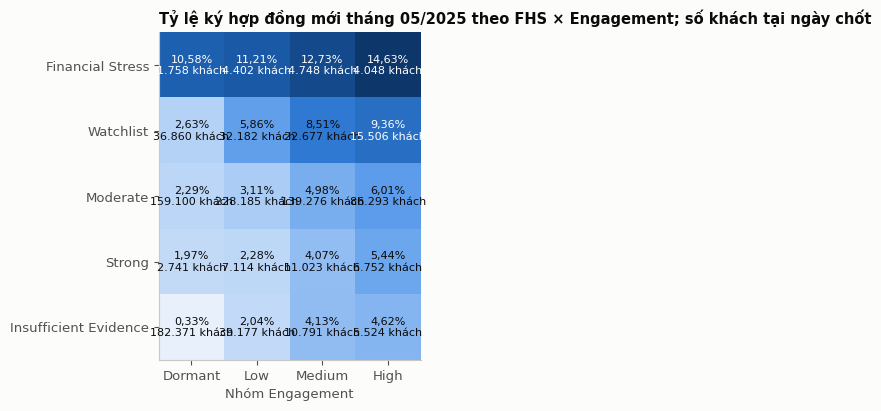

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(ty_le.values, cmap=CMAP_XANH, vmin=0, vmax=np.nanmax(ty_le.values))
for i in range(ty_le.shape[0]):
    for j in range(ty_le.shape[1]):
        v = ty_le.values[i, j]; n = bang.values[i, j]
        ax.text(j, i, f'{so(v, 2)}%\n{so(n, 0)} khách', ha='center', va='center', fontsize=8,
                color='white' if v > np.nanmax(ty_le.values) * 0.6 else MAU['chu'])
ax.set_xticks(range(4)); ax.set_xticklabels(THU_TU_ENG); ax.set_yticks(range(5)); ax.set_yticklabels(THU_TU_FHS)
ax.set_xlabel('Nhóm Engagement'); ax.grid(False)
ax.set_title('Tỷ lệ ký hợp đồng mới tháng 05/2025 theo FHS × Engagement; số khách tại ngày chốt')
fig.tight_layout(); luu_hinh(fig, 'c3_hinh1_fhs_x_engagement')

*Hình 1. Tỷ lệ ký hợp đồng mới tháng 05/2025 theo nhóm FHS và nhóm Engagement tại 01/05/2025; số khách mỗi ô tính tại ngày chốt. Nguồn: dữ liệu của đề, nhóm tự tính.*

- **Đọc theo Engagement:** trong cùng một nhóm FHS, tỷ lệ ký mới luôn tăng từ Dormant đến High, ở cả 5 hàng của Hình 1. Ví dụ Moderate tăng từ 2,29% lên 6,01%, Strong từ 1,97% lên 5,44%. Engagement giúp chọn khách ở mọi mức tài chính.
- **Đọc theo FHS thì phải cẩn thận:** nhóm Financial Stress có tỷ lệ ký tháng 05 cao nhất (10,58–14,63%). Bảng thứ hai của ô code trên cho thấy lý do: khách ký trong tháng 05 có FHS trung bình 65,4, so với 68,5 ở khách không ký, và 25,3% có FHS dưới 60, so với 15,6%. FHS tại ngày chốt đã tính khoản trả góp của hợp đồng vừa ký (trụ cột Capacity dùng ANNUITY của các hợp đồng Active), nên vay mới làm FHS giảm. Bảng này vì vậy không cho thấy khách FHS thấp là cơ hội bán hàng; nó cho thấy nhiều khách FHS thấp là khách vừa nhận thêm nợ.
- **Giá trị:** S4 Under pressure, engaged chỉ chiếm 4,6% khách nhưng 19,5% giá trị hợp đồng mới tháng 05/2025. S6 Stable, engaged chiếm 22,2% khách và 38,4% giá trị, là nguồn doanh số lớn nhất.

## 4. Next Best Action (yêu cầu 3)

> **Câu hỏi của mục này:** Với từng khách, công ty nên làm gì tiếp theo, qua kênh nào, chào sản phẩm gì?
>
> **Cách làm:** mỗi phân khúc có một hành động chính. Kênh liên hệ chọn theo cách khách đang tương tác (hai điểm con Tiếp cận và Phản hồi của Challenge 2, và việc khách có dùng app). Sản phẩm đề xuất là nhóm sản phẩm khách được chào gần nhất mà chưa ký. Khách có FHS dựa trên dữ liệu bù (IMPUTED) được thêm bước xác minh trước khi chào sản phẩm, theo hướng dẫn của Challenge 1.

| Phân khúc | Next Best Action | Loại hành động |
|---|---|---|
| S1 Severe credit event | Rà soát tín dụng và hỗ trợ xử lý nghĩa vụ; không chào sản phẩm vay mới | Giảm rủi ro |
| S2 Unknown finances, engaged | Bổ sung thông tin thu nhập và nghĩa vụ ở lần liên hệ tới, trước khi chào sản phẩm | Bổ sung dữ liệu |
| S3 Unknown finances, quiet | Liên hệ chi phí thấp kèm mời cập nhật thông tin; không gọi telesales | Bổ sung dữ liệu |
| S4 Under pressure, engaged | Tư vấn kế hoạch trả nợ, nhắc lịch trả; tạm dừng bán thêm | Hỗ trợ |
| S5 Under pressure, quiet | Theo dõi, chỉ gửi nhắc lịch trả; không gọi bán hàng | Theo dõi |
| S6 Stable, engaged | Chào sản phẩm khách đang quan tâm qua kênh khách phản hồi | Bán thêm |
| S7 Stable, low engagement | Nuôi dưỡng: gửi ưu đãi sản phẩm quan tâm qua kênh số, tạo lead có chọn lọc | Nuôi dưỡng |
| S8 Stable, dormant | Kích hoạt lại bằng kênh chi phí thấp (tin nhắn, app); không gọi đại trà | Kích hoạt lại |
| S9 Strong, engaged | Ưu tiên chào sản phẩm quan tâm hoặc xem xét tăng hạn mức, qua thẩm định thông thường | Bán thêm, ưu tiên |
| S10 Strong, under-engaged | Gọi chủ động với ưu đãi phù hợp: tài chính tốt nhưng ít được liên hệ | Kích hoạt, ưu tiên |

Kênh liên hệ cho các hành động bán hàng và kích hoạt (S6 đến S10):

- **App:** khách có dùng app năm 2025 hoặc lần xin vay gần nhất qua app;
- **Call:** điểm Phản hồi từ 13,3 trên 40, tức mức Phản hồi vừa hoặc cao của Challenge 2, và điểm Tiếp cận dưới 40, tức khách có phản hồi nhưng chưa bị liên hệ quá nhiều;
- **SMS:** các trường hợp còn lại, gồm khách đã được tiếp cận nhiều (Tiếp cận từ 40) mà phản hồi thấp. Theo mục 5.1 của Challenge 2, gọi thêm cho nhóm này không có cơ sở.

Hai ngoại lệ: S8 Stable, dormant không dùng Call (khách gần như không tương tác nên gọi tốn chi phí), và S10 Strong, under-engaged luôn dùng Call thay cho SMS (tài chính tốt nhưng ít được liên hệ, nên đáng một cuộc gọi chủ động).

S1 đến S5 dùng kênh chăm sóc khách hàng hoặc kênh thu nợ thông thường, không dùng kênh bán hàng.

In [9]:
NBA = {'S1 Severe credit event': ('Credit review and repayment support; no new credit offer', 'Risk control'),
       'S2 Unknown finances, engaged': ('Collect income and obligation data at the next contact before any offer', 'Data enrichment'),
       'S3 Unknown finances, quiet': ('Low-cost contact with an update-your-information request; no telesales', 'Data enrichment'),
       'S4 Under pressure, engaged': ('Repayment counselling and payment reminders; pause cross-sell', 'Support'),
       'S5 Under pressure, quiet': ('Monitor; payment reminders only; no sales calls', 'Monitor'),
       'S6 Stable, engaged': ('Offer the product of interest through the channel the customer responds to', 'Cross-sell'),
       'S7 Stable, low engagement': ('Nurture: digital offer for the product of interest; selective lead creation', 'Nurture'),
       'S8 Stable, dormant': ('Low-cost reactivation (SMS, app); no mass calling', 'Reactivate'),
       'S9 Strong, engaged': ('Priority offer: product of interest or limit review, standard underwriting', 'Cross-sell (priority)'),
       'S10 Strong, under-engaged': ('Proactive call with a suitable offer: healthy but under-contacted', 'Reactivate (priority)')}
BAN_HANG = ['S6 Stable, engaged', 'S7 Stable, low engagement', 'S8 Stable, dormant', 'S9 Strong, engaged', 'S10 Strong, under-engaged']

kh['NBA'] = kh.SEGMENT.map(lambda s: NBA[s][0])
kh['NBA_TYPE'] = kh.SEGMENT.map(lambda s: NBA[s][1])
dung_app = (kh.PHIEN_APP_TUAN > 0) | kh.KENH_XIN_VAY.astype(str).str.startswith('APP')
kenh = np.select([dung_app, (kh.ENG_RESPONSE >= 13.3) & (kh.ENG_REACH < 40)], ['App', 'Call'], 'SMS')
kh['NBA_CHANNEL'] = np.where(kh.SEGMENT.isin(BAN_HANG), kenh, 'Service / collections')
kh.loc[kh.SEGMENT.isin(['S8 Stable, dormant']) & (kh.NBA_CHANNEL == 'Call'), 'NBA_CHANNEL'] = 'SMS'
kh.loc[kh.SEGMENT.isin(['S10 Strong, under-engaged']) & (kh.NBA_CHANNEL == 'SMS'), 'NBA_CHANNEL'] = 'Call'
kh['NBA_PRODUCT'] = np.where(kh.SEGMENT.isin(BAN_HANG), kh.SP_QUAN_TAM.fillna('No open interest'), '-')
kh['NBA_GUARDRAIL'] = np.where(kh.SEGMENT.isin(BAN_HANG) & kh.FHS_IMPUTED, 'Verify imputed FHS pillar before the offer',
                       np.where(kh.SEGMENT.isin(BAN_HANG) & (kh.TU_CHOI_180 > 0), 'Rejected in last 180 days: check the reason first', '-'))
display(pd.crosstab(kh.SEGMENT, kh.NBA_CHANNEL).reindex(TEN_PK))
print('Bước kiểm tra trước khi chào sản phẩm')
display(pd.crosstab(kh.SEGMENT, kh.NBA_GUARDRAIL).reindex(BAN_HANG))
print('Sản phẩm đề xuất (chỉ phân khúc bán hàng)')
pd.crosstab(kh.SEGMENT, kh.NBA_PRODUCT).reindex(BAN_HANG)

NBA_CHANNEL,App,Call,SMS,Service / collections
SEGMENT,,,,
S1 Severe credit event,0,0,0,13319
"S2 Unknown finances, engaged",0,0,0,16315
"S3 Unknown finances, quiet",0,0,0,221548
"S4 Under pressure, engaged",0,0,0,46797
"S5 Under pressure, quiet",0,0,0,62065
"S6 Stable, engaged",57202,47250,121117,0
"S7 Stable, low engagement",44612,20798,162775,0
"S8 Stable, dormant",19546,0,139554,0
"S9 Strong, engaged",4236,2013,11526,0


Bước kiểm tra trước khi chào sản phẩm


NBA_GUARDRAIL,-,Rejected in last 180 days: check the reason first,Verify imputed FHS pillar before the offer
SEGMENT,,,
"S6 Stable, engaged",104867,17485,103217
"S7 Stable, low engagement",114099,20403,93683
"S8 Stable, dormant",62964,36404,59732
"S9 Strong, engaged",12187,2935,2653
"S10 Strong, under-engaged",6327,3096,432


Sản phẩm đề xuất (chỉ phân khúc bán hàng)


NBA_PRODUCT,-,BNPL,CC,CD,CL,EPOS,No open interest,TW
SEGMENT,,,,,,,,
"S6 Stable, engaged",0,47477,44048,64,99223,11,25942,8804
"S7 Stable, low engagement",0,75057,56141,81,60377,12,34598,1919
"S8 Stable, dormant",0,54278,3092,3,2939,5,98722,61
"S9 Strong, engaged",0,5957,4541,0,5052,3,1677,545
"S10 Strong, under-engaged",0,2671,2093,0,1264,1,3747,79


- **Kênh:** 5 phân khúc bán hàng có 640.484 khách. SMS chiếm 434.968 khách (67,9%) vì phần lớn khách có Phản hồi thấp; 127.548 khách được chọn App và 77.968 khách được chọn Call. Riêng S10 có 7.908 khách được gọi chủ động.
- **Bước kiểm tra:** 259.717 khách bán hàng có FHS dựa trên dữ liệu bù và cần xác minh trước khi chào; 80.323 khách khác có hồ sơ bị từ chối trong 180 ngày và cần xem lý do từ chối trước.
- **Sản phẩm:** CL là sản phẩm đề xuất nhiều nhất ở S6 (99.020 khách), BNPL nhiều nhất ở S7 (75.024) và S8 (54.278). 164.686 khách bán hàng không còn sản phẩm quan tâm nào chưa ký; với họ, hành động là liên hệ chung, không kèm sản phẩm cụ thể.
- File xuất có thêm cột `C1_BUSINESS_ACTION_GUARDRAIL` của Challenge 1 (ví dụ `VERIFY_EXTERNAL_DEBT_AND_INCOME`), để bộ phận thẩm định thấy cả hai lớp kiểm tra.

## 5. Vì sao chọn các hành động này (yêu cầu 4)

| Phân khúc | Hành động | Vì sao (số liệu ở mục 2 và 3) |
|---|---|---|
| S1 Severe credit event | Rà soát tín dụng, không chào vay | Có hợp đồng Written off; Challenge 1 cho thấy Written off đi kèm trễ hạn rất mạnh. 87,8% đã bị từ chối trong 180 ngày, Engagement trung bình 3,8. |
| S2 Unknown finances, engaged | Bổ sung dữ liệu ở lần liên hệ tới | Không có FHS nên không đánh giá được khả năng trả nợ; nhưng khách đang tương tác (Engagement 55,2, 36,0% xin vay trong 90 ngày), nên lần liên hệ tới là cơ hội hỏi thông tin. |
| S3 Unknown finances, quiet | Liên hệ chi phí thấp, mời cập nhật thông tin | 64,5% bị từ chối trong 180 ngày, chỉ 0,3 nhóm sản phẩm đã ký, tỷ lệ ký tháng 05 chỉ 0,63%: gọi bán hàng gần như không có kết quả. |
| S4 Under pressure, engaged | Tư vấn trả nợ, tạm dừng bán thêm | FHS dưới 60, 96,9% đang vay, 37,7% vẫn xin vay trong 90 ngày, và đã nhận 19,5% giá trị hợp đồng mới tháng 05. Thêm khoản vay làm FHS giảm tiếp (mục 3). |
| S5 Under pressure, quiet | Theo dõi, chỉ nhắc lịch trả | FHS dưới 60 và Engagement thấp (18,5): không có cơ sở để bán, nhưng vẫn cần nhắc trả vì 78,6% đang vay. |
| S6 Stable, engaged | Chào sản phẩm quan tâm | 88,5% còn sản phẩm quan tâm chưa ký, 29,3% tự xin vay trong 90 ngày, chiếm 38,4% giá trị hợp đồng mới tháng 05. 45,8% có FHS bù nên cần xác minh trước. |
| S7 Stable, low engagement | Nuôi dưỡng qua kênh số | 84,8% còn sản phẩm quan tâm nhưng chỉ 12,8% tự xin vay; Phản hồi trung bình chỉ 4,9 trên 40, nên kênh số rẻ hơn gọi điện. |
| S8 Stable, dormant | Kích hoạt lại chi phí thấp | Chỉ 37,9% có sản phẩm quan tâm, 4,6% xin vay trong 90 ngày, tỷ lệ ký tháng 05 là 2,29%: không đáng chi phí gọi điện. |
| S9 Strong, engaged | Ưu tiên chào sản phẩm hoặc xem xét hạn mức | Tài chính tốt nhất, 90,6% còn sản phẩm quan tâm, Engagement 56,3. |
| S10 Strong, under-engaged | Gọi chủ động | Tài chính tốt nhưng Tiếp cận trung bình chỉ 17,3 trên 60 và chỉ 42,9% đang vay. Challenge 2 cho thấy ở cùng mức Tiếp cận, khách phản hồi nhiều ký nhiều hơn; nhóm này chưa được liên hệ đủ để biết họ phản hồi ra sao. |

Các hành động được chọn từ dấu hiệu nhu cầu, rủi ro và cách khách tương tác của từng phân khúc. Đây là tương quan quan sát được, không phải bằng chứng hành động sẽ làm khách ký nhiều hơn.

## 6. Xuất file và ví dụ

File `output/customer_segmentation_nba.csv` có một dòng cho mỗi khách: hai điểm, nhóm của từng điểm, phân khúc, Next Best Action, kênh, sản phẩm đề xuất, bước kiểm tra và lý do.

In [10]:
def ly_do(r):
    p = [f"FHS {'n/a' if pd.isna(r.FHS) else so(r.FHS, 1)} ({r.FHS_BAND})", f"Engagement {so(r.ENG_SCORE, 1)} ({r.ENG_GROUP}: Reach {so(r.ENG_REACH, 1)}, Response {so(r.ENG_RESPONSE, 1)})"]
    if r.WRITTEN_OFF: p.append('has a written-off contract')
    if r.SEGMENT in BAN_HANG and r.NBA_PRODUCT != 'No open interest': p.append(f'offered {r.NBA_PRODUCT} but not yet signed')
    if r.TU_CHOI_180 > 0: p.append('rejected application in last 180 days')
    return '; '.join(p)
cot_ra = ['SKP_CLIENT', 'FHS', 'FHS_BAND', 'FHS_EVIDENCE', 'C1_GUARDRAIL', 'WRITTEN_OFF', 'ENG_SCORE', 'ENG_GROUP', 'ENG_REACH', 'ENG_RESPONSE',
          'SEGMENT', 'NBA_TYPE', 'NBA', 'NBA_CHANNEL', 'NBA_PRODUCT', 'NBA_GUARDRAIL', 'TU_CHOI_180', 'SP_QUAN_TAM']
# lý do chỉ phụ thuộc vào vài cột, nên tính trên các tổ hợp khác nhau rồi ghép lại
out = kh[cot_ra].copy()
out['NBA_REASON'] = [ly_do(r) for r in out.itertuples(index=False)]
out = out.drop(columns=['TU_CHOI_180', 'SP_QUAN_TAM']).rename(columns={'FHS': 'FINANCIAL_HEALTH_SCORE', 'FHS_EVIDENCE': 'SCORE_EVIDENCE_FLAG', 'WRITTEN_OFF': 'SEVERE_CREDIT_EVENT', 'C1_GUARDRAIL': 'C1_BUSINESS_ACTION_GUARDRAIL'})
out.to_csv(f'{OUT_DIR}/customer_segmentation_nba.csv', index=False, encoding='utf-8-sig')
print(len(out), 'dòng đã ghi')
out.groupby('SEGMENT').head(1).set_index('SEGMENT').reindex(TEN_PK)

1000528 dòng đã ghi


,SKP_CLIENT,FINANCIAL_HEALTH_SCORE,FHS_BAND,SCORE_EVIDENCE_FLAG,C1_BUSINESS_ACTION_GUARDRAIL,SEVERE_CREDIT_EVENT,ENG_SCORE,ENG_GROUP,ENG_REACH,ENG_RESPONSE,NBA_TYPE,NBA,NBA_CHANNEL,NBA_PRODUCT,NBA_GUARDRAIL,NBA_REASON
SEGMENT,,,,,,,,,,,,,,,,
S1 Severe credit event,***,49.118,Watchlist,CAPACITY_IMPUTED,SEVERE_CREDIT_EVENT_REVIEW,1,13.3,Dormant,13.3,0.0,Risk control,Credit review and repayment support; no new credit offer,Service / collections,-,-,"FHS 49,1 (Watchlist); Engagement 13,3 (Dormant: Reach 13,3, Response 0,0); has a written-off contract"
"S2 Unknown finances, engaged",***,NaN,Insufficient Evidence,NO_EVIDENCE,REQUEST_FINANCIAL_DATA,0,50.0,Medium,40.0,10.0,Data enrichment,Collect income and obligation data at the next contact before any offer,Service / collections,-,-,"FHS n/a (Insufficient Evidence); Engagement 50,0 (Medium: Reach 40,0, Response 10,0)"
"S3 Unknown finances, quiet",***,NaN,Insufficient Evidence,NO_EVIDENCE,REQUEST_FINANCIAL_DATA,0,13.3,Dormant,13.3,0.0,Data enrichment,Low-cost contact with an update-your-information request; no telesales,Service / collections,-,-,"FHS n/a (Insufficient Evidence); Engagement 13,3 (Dormant: Reach 13,3, Response 0,0)"
"S4 Under pressure, engaged",***,59.574,Watchlist,PAYMENT_IMPUTED,VERIFY_IMPUTED_PILLAR,0,73.3,High,33.3,40.0,Support,Repayment counselling and payment reminders; pause cross-sell,Service / collections,-,-,"FHS 59,6 (Watchlist); Engagement 73,3 (High: Reach 33,3, Response 40,0)"
"S5 Under pressure, quiet",***,55.568,Watchlist,PAYMENT_IMPUTED,VERIFY_IMPUTED_PILLAR,0,13.3,Dormant,13.3,0.0,Monitor,Monitor; payment reminders only; no sales calls,Service / collections,-,-,"FHS 55,6 (Watchlist); Engagement 13,3 (Dormant: Reach 13,3, Response 0,0); rejected application in last 180 days"
"S6 Stable, engaged",***,69.381,Moderate,FULL,VERIFY_EXTERNAL_DEBT_AND_INCOME,0,43.3,Medium,33.3,10.0,Cross-sell,Offer the product of interest through the channel the customer responds to,SMS,BNPL,-,"FHS 69,4 (Moderate); Engagement 43,3 (Medium: Reach 33,3, Response 10,0); offered BNPL but not yet signed"
"S7 Stable, low engagement",***,70.300,Moderate,CAPACITY_IMPUTED,VERIFY_IMPUTED_PILLAR,0,36.7,Low,26.7,10.0,Nurture,Nurture: digital offer for the product of interest; selective lead creation,SMS,CC,Verify imputed FHS pillar before the offer,"FHS 70,3 (Moderate); Engagement 36,7 (Low: Reach 26,7, Response 10,0); offered CC but not yet signed"
"S8 Stable, dormant",***,68.461,Moderate,FULL,VERIFY_EXTERNAL_DEBT_AND_INCOME,0,13.3,Dormant,13.3,0.0,Reactivate,"Low-cost reactivation (SMS, app); no mass calling",SMS,BNPL,-,"FHS 68,5 (Moderate); Engagement 13,3 (Dormant: Reach 13,3, Response 0,0); offered BNPL but not yet signed"
"S9 Strong, engaged",***,80.987,Strong,FULL,STANDARD_POLICY_REVIEW,0,80.0,High,46.7,33.3,Cross-sell (priority),"Priority offer: product of interest or limit review, standard underwriting",SMS,CL,-,"FHS 81,0 (Strong); Engagement 80,0 (High: Reach 46,7, Response 33,3); offered CL but not yet signed"


In [11]:
# Bảng tóm tắt nhỏ để vẽ hình cho slide và dashboard
tom_tat = pk[['so_khach', 'pct_khach', 'fhs_tb', 'eng_tb', 'pct_fhs_imputed']].join(co_hoi.drop(columns='so_khach')).join(
    ket_qua[['pct_ky_moi', 'tien_ky_moi_tb_trieu', 'pct_tong_tien']])
tom_tat['NBA_TYPE'] = [NBA[s][1] for s in tom_tat.index]; tom_tat['NBA'] = [NBA[s][0] for s in tom_tat.index]
tom_tat.round(2).to_csv(f'{OUT_DIR}/c3_segment_summary.csv', encoding='utf-8-sig')
ty_le.round(2).to_csv(f'{OUT_DIR}/c3_signing_rate_fhs_x_eng.csv', encoding='utf-8-sig')
bang.to_csv(f'{OUT_DIR}/c3_customers_fhs_x_eng.csv', encoding='utf-8-sig')
pd.crosstab(kh.SEGMENT, kh.NBA_CHANNEL).reindex(TEN_PK).to_csv(f'{OUT_DIR}/c3_channel_by_segment.csv', encoding='utf-8-sig')
pd.crosstab(kh.SEGMENT, kh.NBA_PRODUCT).reindex(BAN_HANG).to_csv(f'{OUT_DIR}/c3_product_by_segment.csv', encoding='utf-8-sig')
print('đã ghi 5 bảng tóm tắt')

đã ghi 5 bảng tóm tắt


## 7. Tổng kết và giới hạn

1. **Kết hợp hai điểm:** FHS và Engagement gần như độc lập (tương quan 0,111), nên được ghép thành 10 phân khúc theo thứ tự ưu tiên: sự kiện tín dụng nghiêm trọng, thiếu dữ liệu tài chính, nhóm FHS, mức Engagement. Nhóm Moderate (61% khách) được tách thành 3 phân khúc theo Engagement.
2. **Cơ hội:**
   - S6 Stable, engaged (225.569 khách) là nhóm bán thêm lớn nhất, chiếm 38,4% giá trị hợp đồng mới tháng 05.
   - S3 Unknown finances, quiet (221.548 khách) cần bổ sung dữ liệu, không cần gọi bán hàng.
   - S10 Strong, under-engaged (9.855 khách) có tài chính tốt nhưng chưa được liên hệ đủ.
   - S4 Under pressure, engaged đang tiếp tục vay dù FHS dưới 60.
3. **Next Best Action:** mỗi khách có một hành động, một kênh liên hệ, một sản phẩm đề xuất và một bước kiểm tra, ghi trong `output/customer_segmentation_nba.csv`.
4. **Lý do:** mỗi hành động gắn với số liệu của phân khúc ở mục 5, và cột `NBA_REASON` ghi lý do cho từng khách.

**Giới hạn:**

- FHS là điểm tại ngày chốt và đã tính các hợp đồng ký trong tháng 05/2025, nên không dùng được để kiểm chứng dự báo theo thời gian. Phần kiểm chứng theo thời gian chỉ có cho Engagement (Challenge 2).
- Hành động đề xuất dựa trên tương quan quan sát được. Chưa có dữ liệu cho biết hành động đó làm khách ký nhiều hơn hay giảm rủi ro; cần đo kết quả sau khi triển khai.
- Sản phẩm đề xuất là sản phẩm khách từng được chào mà chưa ký, không có nghĩa khách đủ điều kiện. Mọi đề xuất vẫn phải qua quy trình thẩm định thông thường.
- 38,2% khách có FHS (291.060 trên 762.665) có điểm dựa một phần vào dữ liệu bù, nên các hành động bán hàng có thêm bước xác minh.
- Không quy tắc nào dùng tuổi, giới tính, học vấn hay tỉnh.